&nbsp;

## GENCODE metadata process

- protein-coding gene, long non-coding gene などの バージョンの推移を棒グラフで可視化するための notebook

In [1]:
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from bs4 import BeautifulSoup

&nbsp;

&nbsp;

&nbsp;

## Parse Metadata

- [](../../Data/metadata/metadata_gencode/)

In [2]:
def parse_gencode_release_history(html_path: Path) -> pl.DataFrame:
    """Parse release history table from gencodegenes.org HTML."""
    soup = BeautifulSoup(html_path.read_text(), "html.parser")
    table = soup.find("table", class_="striped")

    rows = [
        [td.get_text(strip=True) for td in tr.find_all("td")]
        for tr in table.find("tbody").find_all("tr", class_="toggleable")
    ]

    date_pattern = r"^(\d+)\.(\d+)$"

    return (
        pl.DataFrame(
            rows,
            schema={
                "freeze_date": pl.Utf8,
                "release": pl.Utf8,
                "reference_release": pl.Utf8,
                "release_date": pl.Utf8,
                "genome_assembly": pl.Utf8,
                "ensembl_release": pl.Utf8,
                "ucsc_version": pl.Utf8,
                "notes": pl.Utf8,
            },
            orient="row",
        )
        .with_columns(
            pl.col("freeze_date")
            .str.extract(date_pattern, 1)
            .cast(pl.Int64)
            .alias("freeze_month"),
            pl.col("freeze_date")
            .str.extract(date_pattern, 2)
            .cast(pl.Int64)
            .alias("freeze_year"),
            pl.col("release_date")
            .str.extract(date_pattern, 1)
            .cast(pl.Int64)
            .alias("release_month"),
            pl.col("release_date")
            .str.extract(date_pattern, 2)
            .cast(pl.Int64)
            .alias("release_year"),
            pl.col("reference_release")
            .str.starts_with("Y")
            .alias("is_reference_release"),
            pl.col("release").cast(pl.Int64, strict=False).alias("release_num"),
        )
        .select(
            "release",
            "release_num",
            "freeze_month",
            "freeze_year",
            "release_month",
            "release_year",
            "is_reference_release",
            "genome_assembly",
            "ensembl_release",
        )
        .sort("release_num", descending=True, nulls_last=True)
    )


html_path = Path("../../Data/metadata/metadata_gencode/gencode_stats_all.html")
df_release_history = parse_gencode_release_history(html_path)
df_release_history

release,release_num,freeze_month,freeze_year,release_month,release_year,is_reference_release,genome_assembly,ensembl_release
str,i64,i64,i64,i64,i64,bool,str,str
"""49""",49,2,2025,9,2025,false,"""GRCh38.p14""","""115"""
"""48""",48,8,2024,5,2025,false,"""GRCh38.p14""","""114"""
"""47""",47,4,2024,10,2024,false,"""GRCh38.p14""","""113"""
"""46""",46,9,2023,5,2024,false,"""GRCh38.p14""","""112"""
"""45""",45,3,2023,1,2024,false,"""GRCh38.p14""","""111"""
…,…,…,…,…,…,…,…,…
"""5""",5,4,2010,11,2010,false,"""GRCh37""","""60"""
"""4""",4,1,2010,5,2010,false,"""GRCh37""","""58"""
"""3d""",null,7,2009,3,2010,false,"""GRCh37""","""57"""


In [3]:
# Keep the latest GENCODE release per release_year (e.g. 2024 -> release 47)
df_release_history_filter = (
    df_release_history.filter(pl.col("release_year").is_not_null())
    .sort(
        "release_year",
        "release_month",
        "release_num",
        "release",
        descending=[False, True, True, True],
        nulls_last=True,
    )
    .group_by("release_year", maintain_order=True)
    .first()
).filter(
    (pl.col("release_year") != 2009) & (pl.col("release_year") != 2010)
)

pl.Config.set_tbl_rows(17)
display(df_release_history_filter)

release_year,release,release_num,freeze_month,freeze_year,release_month,is_reference_release,genome_assembly,ensembl_release
i64,str,i64,i64,i64,i64,bool,str,str
2011,"""10""",10,7,2011,12,true,"""GRCh37""","""65"""
2012,"""14""",14,6,2012,10,false,"""GRCh37""","""69"""
2013,"""19""",19,7,2013,12,true,"""GRCh37.p13""","""74"""
2014,"""21""",21,6,2014,10,true,"""GRCh38""","""77"""
2015,"""24""",24,8,2015,12,false,"""GRCh38.p5""","""83"""
2016,"""25""",25,3,2016,7,false,"""GRCh38.p7""","""85"""
2017,"""27""",27,1,2017,8,false,"""GRCh38.p10""","""90"""
2018,"""29""",29,5,2018,10,false,"""GRCh38.p12""","""94"""
2019,"""32""",32,5,2019,9,false,"""GRCh38.p13""","""98"""


&nbsp;

&nbsp;

## Parse General stats

- Extract top-level gene counts from each release stats HTML

In [4]:
GENE_TYPE_COLUMNS = {
    "Total No of Genes": "total_genes",
    "Protein-coding genes": "protein_coding_genes",
    "Long non-coding RNA genes": "lncrna_genes",
    "Small non-coding RNA genes": "small_ncrna_genes",
    "Pseudogenes": "pseudogenes",
}


def parse_gencode_general_stats(html_path: Path) -> pl.DataFrame:
    """Parse top-level gene counts from the General stats section."""
    soup = BeautifulSoup(html_path.read_text(), "html.parser")
    general_stats = soup.find("h3", string="General stats")
    if general_stats is None:
        msg = f"General stats section not found: {html_path}"
        raise ValueError(msg)

    records: list[dict[str, int | None]] = []
    for tr in general_stats.find_next("table").find("tbody").find_all("tr"):
        cells = tr.find_all("td")
        if len(cells) != 2:
            continue

        label_cell, value_cell = cells
        if "small-text" in label_cell.get("class", []):
            continue

        label = label_cell.get_text(strip=True)
        if label not in GENE_TYPE_COLUMNS:
            continue

        value_text = value_cell.get_text(strip=True)
        records.append(
            {
                "gene_type": GENE_TYPE_COLUMNS[label],
                "gene_count": int(value_text) if value_text else None,
            }
        )

    release = html_path.stem.removeprefix("gencode_stats_v")
    return pl.DataFrame(records).with_columns(pl.lit(release).alias("release"))


def parse_gencode_stats_for_releases(
    stats_dir: Path,
    releases: pl.Series,
) -> pl.DataFrame:
    """Parse General stats for the given releases and return a wide DataFrame."""
    stats_paths = [
        stats_dir / f"gencode_stats_v{release}.html" for release in releases.to_list()
    ]

    return (
        pl.concat(
            [
                parse_gencode_general_stats(path).pivot(
                    on="gene_type",
                    values="gene_count",
                )
                for path in stats_paths
            ]
        )
        .with_columns(pl.col("release").cast(pl.Utf8))
    )


stats_html_dir = Path("../../Data/metadata/metadata_gencode/stats_html")
df_gene_stats = parse_gencode_stats_for_releases(
    stats_html_dir,
    df_release_history_filter["release"],
)
df_gencode_yearly = df_release_history_filter.join(
    df_gene_stats,
    on="release",
    how="left",
).sort("release_year")

pl.Config.set_tbl_rows(17)
display(df_gencode_yearly)

release_year,release,release_num,freeze_month,freeze_year,release_month,is_reference_release,genome_assembly,ensembl_release,total_genes,protein_coding_genes,lncrna_genes,small_ncrna_genes,pseudogenes
i64,str,i64,i64,i64,i64,bool,str,str,i64,i64,i64,i64,i64
2011,"""10""",10,7,2011,12,true,"""GRCh37""","""65""",52376,20007,10830,7142,12358
2012,"""14""",14,6,2012,10,false,"""GRCh37""","""69""",55889,20078,12933,9173,13341
2013,"""19""",19,7,2013,12,true,"""GRCh37.p13""","""74""",57820,20345,13870,9013,14206
2014,"""21""",21,6,2014,10,true,"""GRCh38""","""77""",60155,19881,15875,9536,14468
2015,"""24""",24,8,2015,12,false,"""GRCh38.p5""","""83""",60554,19815,15941,9882,14505
2016,"""25""",25,3,2016,7,false,"""GRCh38.p7""","""85""",58037,19950,15767,7258,14650
2017,"""27""",27,1,2017,8,false,"""GRCh38.p10""","""90""",58288,19836,15778,7569,14694
2018,"""29""",29,5,2018,10,false,"""GRCh38.p12""","""94""",58721,19940,16066,7577,14729
2019,"""32""",32,5,2019,9,false,"""GRCh38.p13""","""98""",60609,19965,17910,7576,14749


In [5]:
GENE_TYPE_LABELS = {
    "protein_coding_genes": "Protein-coding",
    "lncrna_genes": "Long non-coding RNA",
    "small_ncrna_genes": "Small non-coding RNA",
    "pseudogenes": "Pseudogenes",
}

GENE_TYPE_ORDER = list(GENE_TYPE_LABELS.keys())

df_plot = (
    df_gencode_yearly.unpivot(
        index=["release_year", "release"],
        on=GENE_TYPE_ORDER,
        variable_name="gene_type",
        value_name="gene_count",
    )
    .with_columns(
        pl.col("gene_type")
        .replace(GENE_TYPE_LABELS)
        .cast(pl.Enum(GENE_TYPE_LABELS.values())),  # legend order
    )
    .sort("release_year")
)

display(df_plot)

release_year,release,gene_type,gene_count
i64,str,enum,i64
2011,"""10""","""Protein-coding""",20007
2011,"""10""","""Long non-coding RNA""",10830
2011,"""10""","""Small non-coding RNA""",7142
2011,"""10""","""Pseudogenes""",12358
2012,"""14""","""Protein-coding""",20078
2012,"""14""","""Long non-coding RNA""",12933
2012,"""14""","""Small non-coding RNA""",9173
2012,"""14""","""Pseudogenes""",13341
2013,"""19""","""Protein-coding""",20345


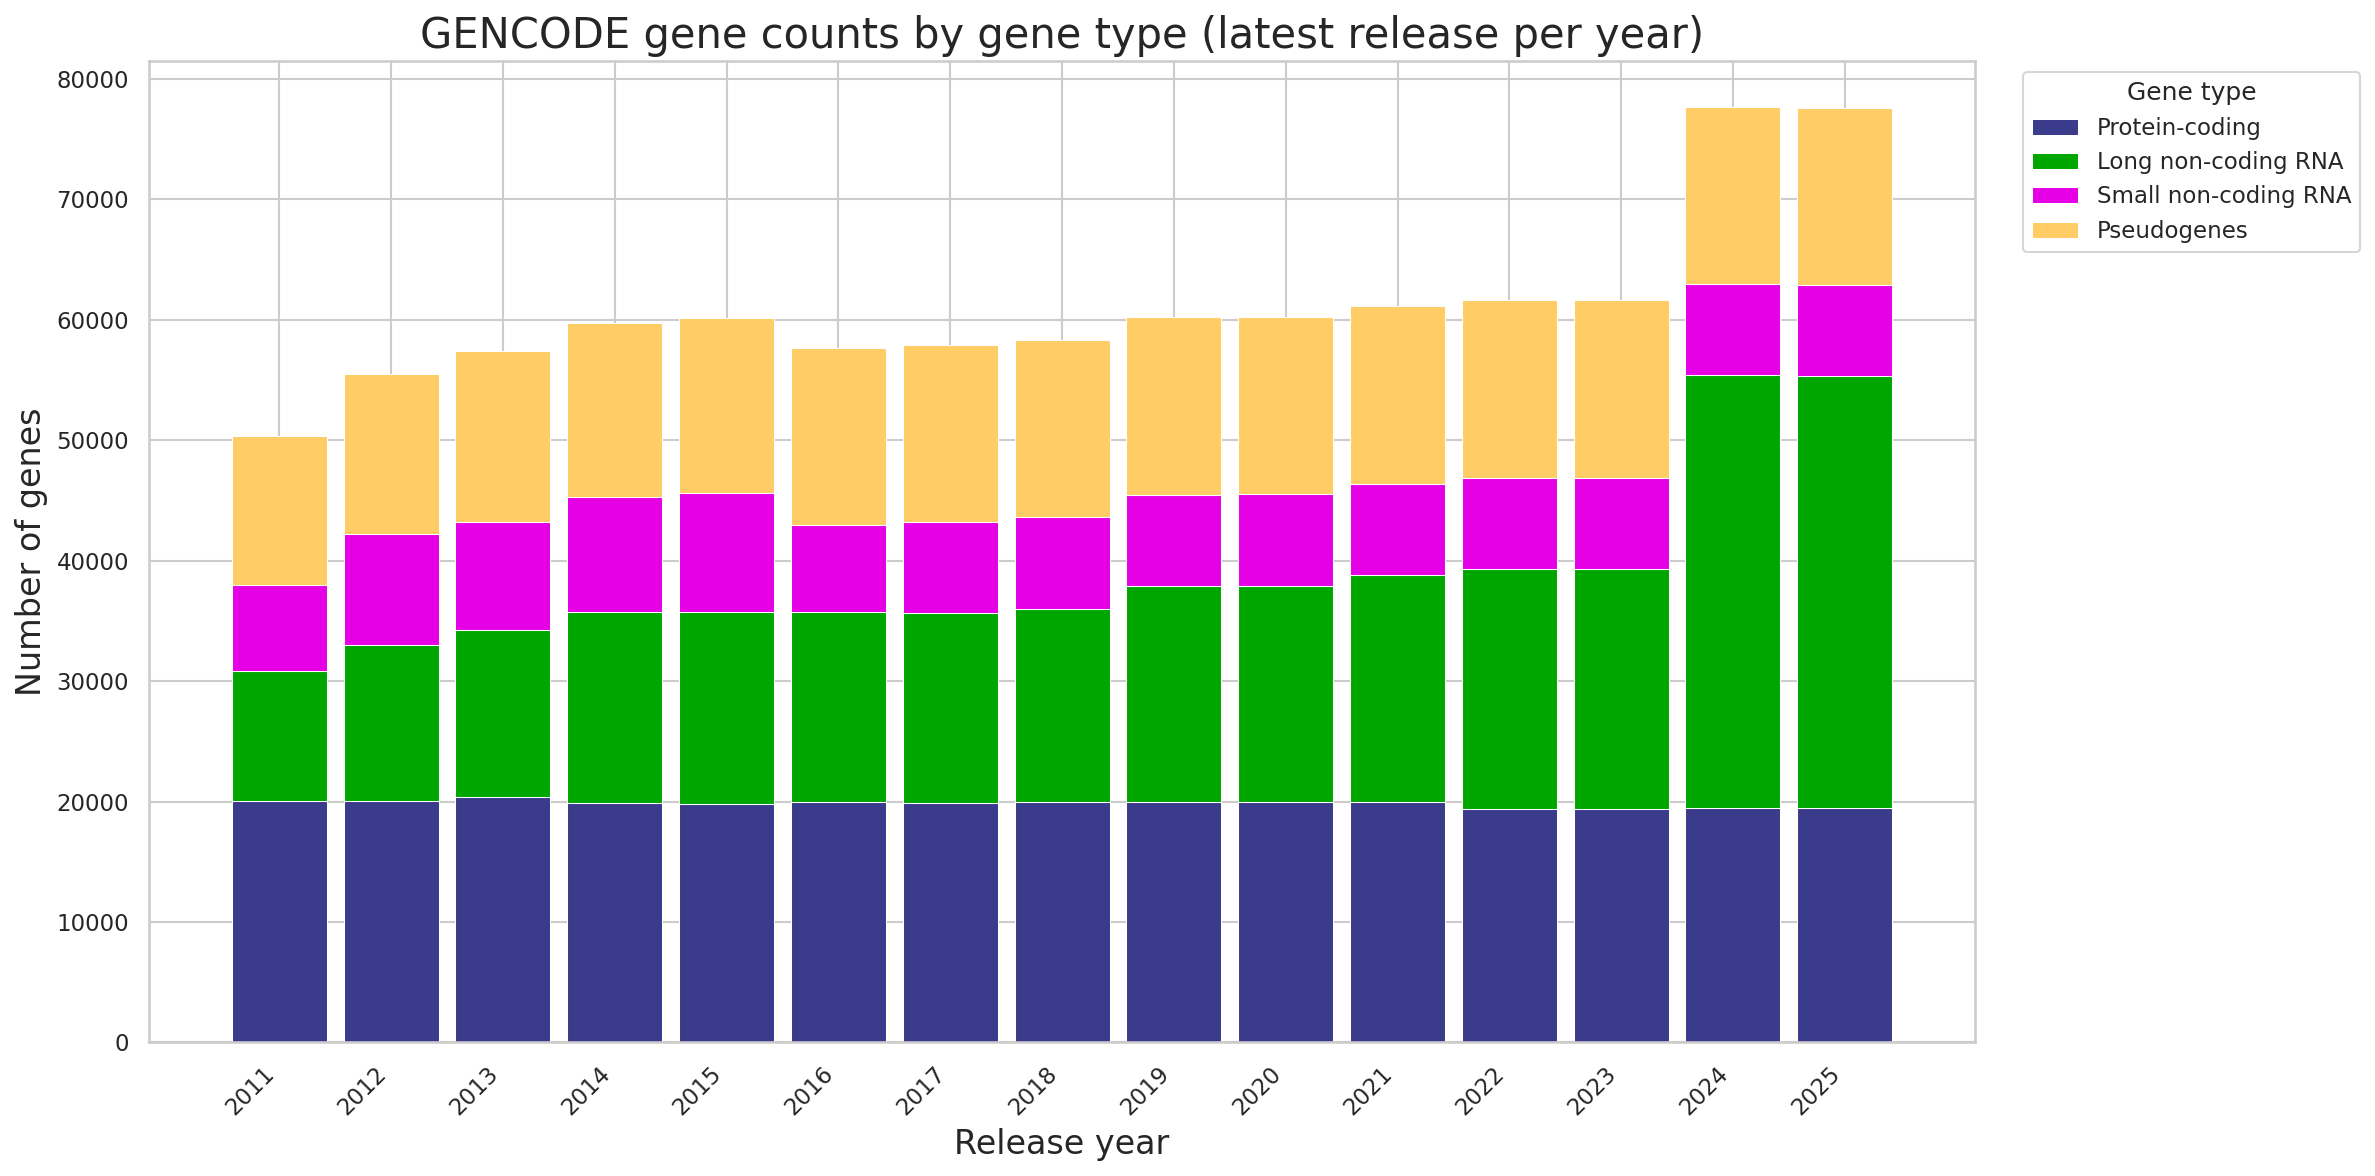

PosixPath('../../Data/metadata/metadata_gencode/gencode_gene_counts_by_type.png')

In [16]:
# Color palette matched to reference chart (bottom -> top)
GENE_TYPE_COLORS = {
    "protein_coding_genes": "#3b3b8c",
    "lncrna_genes": "#00a600",
    "small_ncrna_genes": "#e600e6",
    "pseudogenes": "#ffcc66",
}

DISPLAY_DPI = 150  # notebook preview
SAVE_DPI = 300  # export (publication quality)

sns.set_theme(style="whitegrid")
plt.rcParams["savefig.dpi"] = SAVE_DPI

years = df_plot["release_year"].unique().sort().to_list()
x = range(len(years))

fig, ax = plt.subplots(figsize=(16, 8), dpi=DISPLAY_DPI)
bottom = [0] * len(years)

for gene_col in GENE_TYPE_ORDER:
    gene_label = GENE_TYPE_LABELS[gene_col]
    counts = (
        df_plot.filter(pl.col("gene_type") == gene_label)
        .sort("release_year")["gene_count"]
        .to_list()
    )
    ax.bar(
        x,
        counts,
        bottom=bottom,
        label=gene_label,
        color=GENE_TYPE_COLORS[gene_col],
        edgecolor="white",
        linewidth=0.5,
        width=0.85,
    )
    bottom = [b + c for b, c in zip(bottom, counts)]

ax.set_xticks(x)
ax.set_xticklabels([str(year) for year in years], rotation=45, ha="right")  # rotate year labels by 45 degrees
ax.set_xlabel("Release year", fontsize=16)
ax.set_ylabel("Number of genes", fontsize=16)
ax.set_title("GENCODE gene counts by gene type (latest release per year)", fontsize=20)
ax.legend(title="Gene type", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()

output_path = Path("../../Data/metadata/metadata_gencode/gencode_gene_counts_by_type.png")
output_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(output_path, dpi=SAVE_DPI, bbox_inches="tight")

plt.show()
output_path